## Setup

In [1]:
import pandas as pd
import numpy as np
from collections import Counter

from sklearn.model_selection import train_test_split

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
df = pd.read_csv("../data/players_21.csv")

print(df.head())
print(df.columns)

   sofifa_id                                         player_url  \
0     158023  https://sofifa.com/player/158023/lionel-messi/...   
1      20801  https://sofifa.com/player/20801/c-ronaldo-dos-...   
2     200389  https://sofifa.com/player/200389/jan-oblak/210002   
3     188545  https://sofifa.com/player/188545/robert-lewand...   
4     190871  https://sofifa.com/player/190871/neymar-da-sil...   

          short_name                            long_name  age         dob  \
0           L. Messi       Lionel Andrés Messi Cuccittini   33  1987-06-24   
1  Cristiano Ronaldo  Cristiano Ronaldo dos Santos Aveiro   35  1985-02-05   
2           J. Oblak                            Jan Oblak   27  1993-01-07   
3     R. Lewandowski                   Robert Lewandowski   31  1988-08-21   
4          Neymar Jr        Neymar da Silva Santos Júnior   28  1992-02-05   

   height_cm  weight_kg nationality            club_name  ...   lwb   ldm  \
0        170         72   Argentina         FC Barc

## Preprocessing

In [3]:
# make clean_df
clean_df = df.copy()

# look at the columns used for position mapping
clean_df[['short_name', 'team_position', 'nation_position', 'player_positions']].head()


,short_name,team_position,nation_position,player_positions
0,L. Messi,CAM,RW,"RW, ST, CF"
1,Cristiano Ronaldo,LS,LS,"ST, LW"
2,J. Oblak,GK,GK,GK
3,R. Lewandowski,ST,NaN,ST
4,Neymar Jr,LW,NaN,"LW, CAM"


In [4]:
def map_single_position(pos):

    if pd.isna(pos):
        return None

    pos = str(pos).strip().upper()

    if pos == "GK":
        return "GK"
    elif pos == "CB":
        return "CB"
    elif pos in ["LB", "RB", "LWB", "RWB"]:
        return "FB"
    elif pos in ["CDM", "CM", "CAM"]:
        return "CM"
    elif pos in ["LM", "RM", "LW", "RW"]:
        return "Winger"
    elif pos in ["ST", "CF"]:
        return "ST"
    else:
        return None


In [5]:
def determine_position_6(player_positions, team_position):

    if pd.isna(player_positions):
        return None

    listed_positions = [
        p.strip().upper()
        for p in str(player_positions).split(",")
        if p.strip()
    ]

    mapped_positions = [
        map_single_position(p)
        for p in listed_positions
    ]

    mapped_positions = [p for p in mapped_positions if p is not None]

    if len(mapped_positions) == 0:
        return None

    counts = Counter(mapped_positions)
    max_count = max(counts.values())

    top_classes = [
        cls for cls, count in counts.items()
        if count == max_count
    ]

    # Clear majority: for example [CM, CM, Winger] -> CM
    if len(top_classes) == 1:
        return top_classes[0]

    # Tie breaker: for example [ST, Winger] and team_position = LW -> Winger
    team_mapped = map_single_position(team_position)
    if team_mapped in top_classes:
        return team_mapped

    # Fallback: use the first listed valid mapped position
    return mapped_positions[0]


In [6]:
clean_df["team_position"] = clean_df["team_position"].fillna("SUB")

clean_df["position"] = clean_df.apply(
    lambda row: determine_position_6(
        row["player_positions"],
        row["team_position"]
    ),
    axis=1
)

clean_df = clean_df.dropna(subset=["position"])

print(clean_df["position"].value_counts())


position
CM        4821
Winger    3291
CB        3152
FB        3013
ST        2583
GK        2084
Name: count, dtype: int64


In [7]:
position_id_map = {
    "GK": 0,
    "CB": 1,
    "FB": 2,
    "CM": 3,
    "Winger": 4,
    "ST": 5
}

clean_df["position_id"] = clean_df["position"].map(position_id_map)

In [8]:
# Convert preferred foot into a numeric feature
clean_df["foot_id"] = clean_df["preferred_foot"].apply(lambda x: 0 if x == "Left" else 1)


In [9]:
# Drop columns
cols_to_drop = [
    "player_url", "short_name", "long_name", "dob", "sofifa_id",
    "body_type", "real_face", "player_tags", "joined", "loaned_from",
    "team_position", "nation_position", "player_positions",
    "preferred_foot", 'ls', 'st', 'rs','lw', 'lf', 'cf', 'rf', 'rw', 'lam', 'cam', 'ram', 'lm', 'lcm', 'cm',
       'rcm', 'rm', 'lwb', 'ldm', 'cdm', 'rdm', 'rwb', 'lb', 'lcb', 'cb',
       'rcb', 'rb', 'league_name', 'club_name', 'release_clause_eur', 'team_jersey_number', 'contract_valid_until', 'nation_jersey_number', 'league_rank', 'defending_marking',
    'goalkeeping_diving', 'goalkeeping_handling', 'goalkeeping_kicking','goalkeeping_positioning'
]

clean_df = clean_df.drop(columns=cols_to_drop, errors="ignore")

print(clean_df.columns)


Index(['age', 'height_cm', 'weight_kg', 'nationality', 'overall', 'potential',
       'value_eur', 'wage_eur', 'international_reputation', 'weak_foot',
       'skill_moves', 'work_rate', 'pace', 'shooting', 'passing', 'dribbling',
       'defending', 'physic', 'gk_diving', 'gk_handling', 'gk_kicking',
       'gk_reflexes', 'gk_speed', 'gk_positioning', 'player_traits',
       'attacking_crossing', 'attacking_finishing',
       'attacking_heading_accuracy', 'attacking_short_passing',
       'attacking_volleys', 'skill_dribbling', 'skill_curve',
       'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control',
       'movement_acceleration', 'movement_sprint_speed', 'movement_agility',
       'movement_reactions', 'movement_balance', 'power_shot_power',
       'power_jumping', 'power_stamina', 'power_strength', 'power_long_shots',
       'mentality_aggression', 'mentality_interceptions',
       'mentality_positioning', 'mentality_vision', 'mentality_penalties',
       'mentality_co

In [10]:
# Drop rows missing target
clean_df = clean_df.dropna(subset=['position_id'])

print(clean_df["position"].value_counts())

position
CM        4821
Winger    3291
CB        3152
FB        3013
ST        2583
GK        2084
Name: count, dtype: int64


In [11]:
# imputing
# if traits is null make it "none"
clean_df["player_traits"] = clean_df["player_traits"].fillna("none")


In [12]:
# fill remaining null with 30
clean_df = clean_df.fillna(30)

In [13]:
# check columns for null values
print(clean_df.isnull().sum()[clean_df.isnull().sum() > 0])



Series([], dtype: int64)


## Training

In [13]:
# Create feature matrix X and target vector y
drop_cols = [
    "position", "position_id"
]

X = clean_df.drop(columns=drop_cols)
X = X.select_dtypes(include=[np.number])

y = clean_df["position"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", sorted(y.unique()))


Feature matrix shape: (18944, 52)
Target shape: (18944,)
Classes: ['CB', 'CM', 'FB', 'GK', 'ST', 'Winger']


In [15]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (13260, 52)
Validation: (2842, 52)
Test: (2842, 52)


In [16]:
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

In [17]:
Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("knn", KNeighborsClassifier())
])

Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA()),
                ('knn', KNeighborsClassifier())])

## Evaluate

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

k_values = [3, 5, 7, 9, 11, 15, 21, 30]


In [19]:
def tune_and_evaluate(
    method_name,
    pipeline,
    param_grid,
    X_dev,
    y_dev,
    X_test,
    y_test,
    cv
):
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_weighted",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_dev, y_dev)

    best_model = search.best_estimator_

    test_pred = best_model.predict(X_test)

    test_accuracy = accuracy_score(y_test, test_pred)
    test_f1 = f1_score(
        y_test,
        test_pred,
        average="weighted"
    )

    print("\n" + "=" * 70)
    print(method_name)
    print("Best Parameters:", search.best_params_)
    print("Best CV Weighted F1:", round(search.best_score_, 4))
    print("Test Accuracy:", round(test_accuracy, 4))
    print("Test Weighted F1:", round(test_f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, test_pred))

    return {
        "Method": method_name,
        "Best Parameters": search.best_params_,
        "CV Weighted F1": search.best_score_,
        "Test Accuracy": test_accuracy,
        "Test Weighted F1": test_f1,
        "Best Model": best_model,
        "Test Predictions": test_pred
    }

### Raw Data

In [26]:
# Raw Data
raw_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

raw_grid = {
    "knn__n_neighbors": k_values
}

raw_result = tune_and_evaluate(
    "Raw Data",
    raw_pipeline,
    raw_grid,
    X_dev,
    y_dev,
    X_test,
    y_test,
    cv
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Raw Data
Best Parameters: {'knn__n_neighbors': 21}
Best CV Weighted F1: 0.8322
Test Accuracy: 0.8286
Test Weighted F1: 0.8287

Classification Report:
              precision    recall  f1-score   support

          CB       0.91      0.88      0.89       473
          CM       0.75      0.83      0.78       723
          FB       0.85      0.79      0.82       452
          GK       1.00      1.00      1.00       312
          ST       0.86      0.86      0.86       388
      Winger       0.73      0.68      0.70       494

    accuracy                           0.83      2842
   macro avg       0.85      0.84      0.84      2842
weighted avg       0.83      0.83      0.83      2842



### PCA

In [27]:
# PCA
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("knn", KNeighborsClassifier())
])

pca_grid = {
    "pca__n_components": [25, 30, 35, 40, 45, 50],
    "knn__n_neighbors": [21, 25, 30, 35, 40, 50]
}

pca_result = tune_and_evaluate(
    "PCA",
    pca_pipeline,
    pca_grid,
    X_dev,
    y_dev,
    X_test,
    y_test,
    cv
)

Fitting 5 folds for each of 36 candidates, totalling 180 fits

PCA
Best Parameters: {'knn__n_neighbors': 21, 'pca__n_components': 50}
Best CV Weighted F1: 0.8322
Test Accuracy: 0.8286
Test Weighted F1: 0.8287

Classification Report:
              precision    recall  f1-score   support

          CB       0.91      0.88      0.89       473
          CM       0.75      0.83      0.78       723
          FB       0.85      0.79      0.82       452
          GK       1.00      1.00      1.00       312
          ST       0.86      0.86      0.86       388
      Winger       0.73      0.68      0.70       494

    accuracy                           0.83      2842
   macro avg       0.85      0.84      0.84      2842
weighted avg       0.83      0.83      0.83      2842



In [28]:
best_pca = pca_result["Best Model"].named_steps["pca"]

print("Selected components:", best_pca.n_components_)
print(
    "Explained variance retained:",
    round(best_pca.explained_variance_ratio_.sum(), 4)
)

explained = best_pca.explained_variance_ratio_.sum()

print("Explained variance:", explained)
print(f"Explained variance: {explained:.10f}")
print(f"Variance discarded: {1 - explained:.10f}")

Selected components: 50
Explained variance retained: 1.0
Explained variance: 0.9999609086771176
Explained variance: 0.9999609087
Variance discarded: 0.0000390913


In [29]:
scaler_check = StandardScaler()
X_dev_scaled_check = scaler_check.fit_transform(X_dev)

print("Number of features:", X_dev_scaled_check.shape[1])
print("Matrix rank:", np.linalg.matrix_rank(X_dev_scaled_check))

Number of features: 52
Matrix rank: 52


In [30]:
pca_full = PCA()
pca_full.fit(X_dev_scaled_check)

for i, ratio in enumerate(pca_full.explained_variance_ratio_, start=1):
    print(i, ratio)

1 0.4730558952489523
2 0.11767943005023802
3 0.1083845441000068
4 0.051228259968573234
5 0.03328884317937231
6 0.02935739288961985
7 0.020881535865467857
8 0.01977595010210613
9 0.014973385891960848
10 0.013801094560013749
11 0.01085768203184676
12 0.00955471536623011
13 0.008711854572063464
14 0.007456461279683424
15 0.006783499867489684
16 0.005795600814746567
17 0.005267029121041789
18 0.005010686472603046
19 0.004860643878045177
20 0.004635474008265828
21 0.004260499657752385
22 0.003854316842292305
23 0.0037670547359951708
24 0.0035563284499601634
25 0.00338884470367392
26 0.002956092602881433
27 0.002718524574527096
28 0.0026437272139987916
29 0.0024895486096261736
30 0.0024365612128804223
31 0.0021302565705000015
32 0.0019821451449238193
33 0.0018606462099269368
34 0.0014547090705761719
35 0.0013274150855456016
36 0.001271755493223846
37 0.0012345480177365514
38 0.001091854397213893
39 0.0008062663641897698
40 0.0007150684368274539
41 0.0006321931725765507
42 0.00044220860785625

### KPCA

In [31]:
kpca_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

kpca_components = [30, 40, 50]
kpca_gammas = [0.001, 0.0025, 0.005]
knn_values = [21, 30, 40]

kpca_cv_results = []


for n_components in kpca_components:

    for gamma in kpca_gammas:

        # Store CV scores for each KNN value
        scores_by_k = {
            k: [] for k in knn_values
        }

        print(
            f"\nTesting KPCA: "
            f"components={n_components}, gamma={gamma}"
        )

        for fold, (train_idx, val_idx) in enumerate(
            kpca_cv.split(X_dev, y_dev),
            start=1
        ):

            # --------------------------------------------
            # Get current CV fold
            # --------------------------------------------

            X_fold_train = X_dev.iloc[train_idx]
            X_fold_val = X_dev.iloc[val_idx]

            y_fold_train = y_dev.iloc[train_idx]
            y_fold_val = y_dev.iloc[val_idx]


            # --------------------------------------------
            # Scale using ONLY training fold
            # --------------------------------------------

            scaler = StandardScaler()

            X_fold_train_scaled = scaler.fit_transform(
                X_fold_train
            )

            X_fold_val_scaled = scaler.transform(
                X_fold_val
            )


            # --------------------------------------------
            # Fit Kernel PCA ONCE for this fold/configuration
            # --------------------------------------------

            kpca = KernelPCA(
                n_components=n_components,
                kernel="rbf",
                gamma=gamma,
                eigen_solver="randomized",
                random_state=42,
                n_jobs=-1
            )

            X_fold_train_kpca = kpca.fit_transform(
                X_fold_train_scaled
            )

            X_fold_val_kpca = kpca.transform(
                X_fold_val_scaled
            )


            # --------------------------------------------
            # Reuse the KPCA representation for all k values
            # --------------------------------------------

            for k in knn_values:

                clf = KNeighborsClassifier(
                    n_neighbors=k
                )

                clf.fit(
                    X_fold_train_kpca,
                    y_fold_train
                )

                val_pred = clf.predict(
                    X_fold_val_kpca
                )

                val_f1 = f1_score(
                    y_fold_val,
                    val_pred,
                    average="weighted"
                )

                scores_by_k[k].append(val_f1)

            print(f"  Fold {fold} complete")


        # --------------------------------------------
        # Store mean CV score for every KNN value
        # --------------------------------------------

        for k in knn_values:

            mean_f1 = np.mean(scores_by_k[k])
            std_f1 = np.std(scores_by_k[k])

            kpca_cv_results.append({
                "n_components": n_components,
                "gamma": gamma,
                "k": k,
                "Mean CV Weighted F1": mean_f1,
                "Std CV Weighted F1": std_f1
            })


# ============================================================
# Find best parameter combination
# ============================================================

kpca_results_df = pd.DataFrame(
    kpca_cv_results
)

kpca_results_df = kpca_results_df.sort_values(
    "Mean CV Weighted F1",
    ascending=False
)

print("\nTop Kernel PCA configurations:")
print(
    kpca_results_df.head(10).round(4)
)


best_row = kpca_results_df.iloc[0]

best_components = int(
    best_row["n_components"]
)

best_gamma = float(
    best_row["gamma"]
)

best_k = int(
    best_row["k"]
)


print("\nBest KPCA Parameters:")
print("Components:", best_components)
print("Gamma:", best_gamma)
print("KNN k:", best_k)
print(
    "CV Weighted F1:",
    round(
        best_row["Mean CV Weighted F1"],
        4
    )
)


Testing KPCA: components=30, gamma=0.001
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=30, gamma=0.0025
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=30, gamma=0.005
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=40, gamma=0.001
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=40, gamma=0.0025
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=40, gamma=0.005
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=50, gamma=0.001
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=50, gamma=0.0025
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Testing KPCA: components=50, gamma=0.005
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Top Kernel PCA configurations:
    n_components   gamma   k  Mean CV Weighted F1  Std CV Weighted F1
19            50  0.0010  30   

In [32]:
# ============================================================
# Final Kernel PCA model
# ============================================================

final_scaler = StandardScaler()

X_dev_scaled = final_scaler.fit_transform(
    X_dev
)

X_test_scaled_final = final_scaler.transform(
    X_test
)


final_kpca = KernelPCA(
    n_components=best_components,
    kernel="rbf",
    gamma=best_gamma,
    eigen_solver="randomized",
    random_state=42,
    n_jobs=-1
)

X_dev_kpca = final_kpca.fit_transform(
    X_dev_scaled
)

X_test_kpca = final_kpca.transform(
    X_test_scaled_final
)


final_kpca_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_kpca_knn.fit(
    X_dev_kpca,
    y_dev
)

kpca_test_pred = final_kpca_knn.predict(
    X_test_kpca
)


kpca_test_accuracy = accuracy_score(
    y_test,
    kpca_test_pred
)

kpca_test_f1 = f1_score(
    y_test,
    kpca_test_pred,
    average="weighted"
)


print("\n" + "=" * 70)
print("Kernel PCA - Final Evaluation")

print(
    "Test Accuracy:",
    round(kpca_test_accuracy, 4)
)

print(
    "Test Weighted F1:",
    round(kpca_test_f1, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        kpca_test_pred
    )
)


Kernel PCA - Final Evaluation
Test Accuracy: 0.8293
Test Weighted F1: 0.8295

Classification Report:
              precision    recall  f1-score   support

          CB       0.91      0.88      0.90       473
          CM       0.74      0.83      0.79       723
          FB       0.85      0.79      0.82       452
          GK       1.00      1.00      1.00       312
          ST       0.87      0.86      0.86       388
      Winger       0.73      0.68      0.71       494

    accuracy                           0.83      2842
   macro avg       0.85      0.84      0.84      2842
weighted avg       0.83      0.83      0.83      2842



In [33]:
# Package final Kernel PCA result

kpca_result = {
    "Method": "Kernel PCA",
    "Best Parameters": {
        "n_components": best_components,
        "gamma": best_gamma,
        "knn__n_neighbors": best_k
    },
    "CV Weighted F1": kpca_results_df.iloc[0]["Mean CV Weighted F1"],
    "Test Accuracy": kpca_test_accuracy,
    "Test Weighted F1": kpca_test_f1,
    "Test Predictions": kpca_test_pred
}

### LLE

In [35]:
# ============================================================
# Efficient LLE hyperparameter tuning
# ============================================================

lle_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Hyperparameter candidates
lle_components = [50]
lle_neighbors = [120]
knn_values = [15, 21, 25, 30, 35, 40]

lle_cv_results = []


# ============================================================
# Cross-validation search
# ============================================================

for n_components in lle_components:

    for n_neighbors in lle_neighbors:

        # Keep neighborhood larger than embedding dimension
        if n_neighbors <= n_components:
            continue

        scores_by_k = {
            k: [] for k in knn_values
        }

        print(
            f"\nTesting LLE: "
            f"components={n_components}, "
            f"neighbors={n_neighbors}"
        )

        for fold, (train_idx, val_idx) in enumerate(
            lle_cv.split(X_dev, y_dev),
            start=1
        ):

            # Current CV fold
            X_fold_train = X_dev.iloc[train_idx]
            X_fold_val = X_dev.iloc[val_idx]

            y_fold_train = y_dev.iloc[train_idx]
            y_fold_val = y_dev.iloc[val_idx]


            # Scale using training fold only
            scaler = StandardScaler()

            X_fold_train_scaled = scaler.fit_transform(
                X_fold_train
            )

            X_fold_val_scaled = scaler.transform(
                X_fold_val
            )


            # Fit LLE once for this configuration/fold
            lle = LocallyLinearEmbedding(
                n_components=n_components,
                n_neighbors=n_neighbors,
                method="standard",
                eigen_solver="arpack",
                random_state=42,
                n_jobs=-1
            )

            X_fold_train_lle = lle.fit_transform(
                X_fold_train_scaled
            )

            X_fold_val_lle = lle.transform(
                X_fold_val_scaled
            )


            # Reuse the LLE representation for all KNN k values
            for k in knn_values:

                clf = KNeighborsClassifier(
                    n_neighbors=k
                )

                clf.fit(
                    X_fold_train_lle,
                    y_fold_train
                )

                val_pred = clf.predict(
                    X_fold_val_lle
                )

                val_f1 = f1_score(
                    y_fold_val,
                    val_pred,
                    average="weighted"
                )

                scores_by_k[k].append(val_f1)

            print(f"  Fold {fold} complete")


        # Record mean CV performance for each k
        for k in knn_values:

            mean_f1 = np.mean(
                scores_by_k[k]
            )

            std_f1 = np.std(
                scores_by_k[k]
            )

            lle_cv_results.append({
                "n_components": n_components,
                "n_neighbors": n_neighbors,
                "k": k,
                "Mean CV Weighted F1": mean_f1,
                "Std CV Weighted F1": std_f1
            })


# ============================================================
# Rank configurations
# ============================================================

lle_results_df = pd.DataFrame(
    lle_cv_results
)

lle_results_df = lle_results_df.sort_values(
    "Mean CV Weighted F1",
    ascending=False
)

print("\nTop LLE configurations:")

print(
    lle_results_df.head(10).round(4)
)


# ============================================================
# Identify best configuration
# ============================================================

best_row = lle_results_df.iloc[0]

best_lle_components = int(
    best_row["n_components"]
)

best_lle_neighbors = int(
    best_row["n_neighbors"]
)

best_lle_k = int(
    best_row["k"]
)

print("\nBest LLE Parameters:")
print("Components:", best_lle_components)
print("LLE neighbors:", best_lle_neighbors)
print("KNN k:", best_lle_k)
print(
    "CV Weighted F1:",
    round(best_row["Mean CV Weighted F1"], 4)
)


Testing LLE: components=50, neighbors=120
  Fold 1 complete
  Fold 2 complete
  Fold 3 complete

Top LLE configurations:
   n_components  n_neighbors   k  Mean CV Weighted F1  Std CV Weighted F1
3            50          120  30               0.8280              0.0062
4            50          120  35               0.8275              0.0060
5            50          120  40               0.8267              0.0040
2            50          120  25               0.8266              0.0046
1            50          120  21               0.8250              0.0044
0            50          120  15               0.8236              0.0058

Best LLE Parameters:
Components: 50
LLE neighbors: 120
KNN k: 30
CV Weighted F1: 0.828


In [36]:
# ============================================================
# Select winner
# ============================================================

best_row = lle_results_df.iloc[0]

best_lle_components = int(
    best_row["n_components"]
)

best_lle_neighbors = int(
    best_row["n_neighbors"]
)

best_lle_k = int(
    best_row["k"]
)


print("\nBest LLE Parameters:")

print(
    "Components:",
    best_lle_components
)

print(
    "LLE neighbors:",
    best_lle_neighbors
)

print(
    "KNN k:",
    best_lle_k
)

print(
    "CV Weighted F1:",
    round(
        best_row["Mean CV Weighted F1"],
        4
    )
)


Best LLE Parameters:
Components: 50
LLE neighbors: 120
KNN k: 30
CV Weighted F1: 0.828


In [37]:
# ============================================================
# Final LLE model
# ============================================================

final_lle_scaler = StandardScaler()

X_dev_scaled_lle = final_lle_scaler.fit_transform(X_dev)
X_test_scaled_lle = final_lle_scaler.transform(X_test)


final_lle = LocallyLinearEmbedding(
    n_components=50,
    n_neighbors=120,
    method="standard",
    eigen_solver="arpack",
    random_state=42,
    n_jobs=-1
)

X_dev_lle_final = final_lle.fit_transform(
    X_dev_scaled_lle
)

X_test_lle_final = final_lle.transform(
    X_test_scaled_lle
)


final_lle_knn = KNeighborsClassifier(
    n_neighbors=30
)

final_lle_knn.fit(
    X_dev_lle_final,
    y_dev
)

lle_test_pred = final_lle_knn.predict(
    X_test_lle_final
)


lle_test_accuracy = accuracy_score(
    y_test,
    lle_test_pred
)

lle_test_f1 = f1_score(
    y_test,
    lle_test_pred,
    average="weighted"
)


print("\n" + "=" * 70)
print("LLE - Final Held-Out Test Evaluation")

print("Components: 50")
print("LLE neighbors: 120")
print("KNN k: 30")
print("CV Weighted F1: 0.8280")

print(
    "Test Accuracy:",
    round(lle_test_accuracy, 4)
)

print(
    "Test Weighted F1:",
    round(lle_test_f1, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        lle_test_pred,
        digits=4
    )
)


LLE - Final Held-Out Test Evaluation
Components: 50
LLE neighbors: 120
KNN k: 30
CV Weighted F1: 0.8280
Test Accuracy: 0.8262
Test Weighted F1: 0.8269

Classification Report:
              precision    recall  f1-score   support

          CB     0.9229    0.8605    0.8906       473
          CM     0.7647    0.8271    0.7947       723
          FB     0.8110    0.8164    0.8137       452
          GK     1.0000    1.0000    1.0000       312
          ST     0.8750    0.8119    0.8422       388
      Winger     0.7053    0.7024    0.7039       494

    accuracy                         0.8262      2842
   macro avg     0.8465    0.8364    0.8408      2842
weighted avg     0.8290    0.8262    0.8269      2842



In [38]:
lle_result = {
    "Method": "LLE",
    "Best Parameters": {
        "n_components": 50,
        "n_neighbors": 120,
        "knn__n_neighbors": 30
    },
    "CV Weighted F1": 0.8280,
    "Test Accuracy": lle_test_accuracy,
    "Test Weighted F1": lle_test_f1,
    "Test Predictions": lle_test_pred
}

## Results

In [39]:
# Results
# ============================================================
# Final Results
# ============================================================

results = [
    raw_result,
    pca_result,
    kpca_result,
    lle_result
]

results_df = pd.DataFrame([
    {
        "Method": r["Method"],
        "Best Parameters": str(r["Best Parameters"]),
        "CV Weighted F1": r["CV Weighted F1"],
        "Test Accuracy": r["Test Accuracy"],
        "Test Weighted F1": r["Test Weighted F1"]
    }
    for r in results
])

print("\nFinal Comparison Table:")
print(results_df.round(4))

results_df.to_csv(
    "final_project_results.csv",
    index=False
)


Final Comparison Table:
       Method                                    Best Parameters  \
0    Raw Data                           {'knn__n_neighbors': 21}   
1         PCA  {'knn__n_neighbors': 21, 'pca__n_components': 50}   
2  Kernel PCA  {'n_components': 50, 'gamma': 0.001, 'knn__n_n...   
3         LLE  {'n_components': 50, 'n_neighbors': 120, 'knn_...   

   CV Weighted F1  Test Accuracy  Test Weighted F1  
0          0.8322         0.8286            0.8287  
1          0.8322         0.8286            0.8287  
2          0.8304         0.8293            0.8295  
3          0.8280         0.8262            0.8269  


In [40]:
final_predictions = {
    r["Method"]: r["Test Predictions"]
    for r in results
}

## Additional Tables & Plots

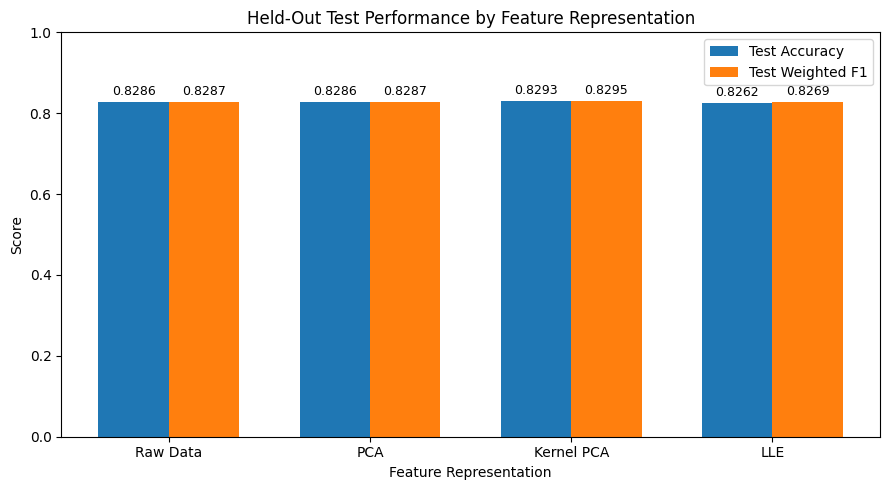

In [ ]:

methods = results_df["Method"]
accuracy = results_df["Test Accuracy"]
weighted_f1 = results_df["Test Weighted F1"]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width/2,
    accuracy,
    width,
    label="Test Accuracy"
)

bars2 = ax.bar(
    x + width/2,
    weighted_f1,
    width,
    label="Test Weighted F1"
)

ax.set_title("Held-Out Test Performance by Feature Representation")
ax.set_ylabel("Score")
ax.set_xlabel("Feature Representation")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1)
ax.legend()

# Add exact values
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.01,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()

os.makedirs("../figures", exist_ok=True)

plt.savefig(
    "../figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

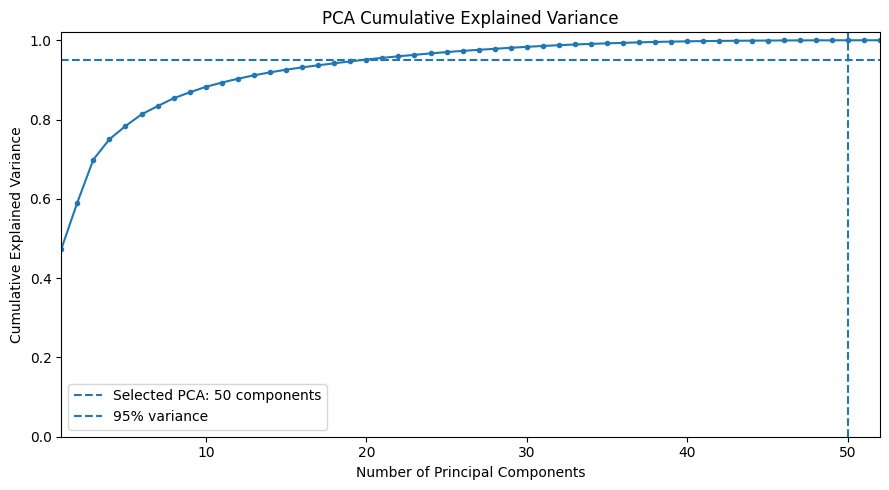

In [ ]:
# Fit PCA on development data only
scaler_for_plot = StandardScaler()

X_dev_scaled_plot = scaler_for_plot.fit_transform(X_dev)

pca_full_plot = PCA()
pca_full_plot.fit(X_dev_scaled_plot)

cumulative_variance = np.cumsum(
    pca_full_plot.explained_variance_ratio_
)

components = np.arange(
    1,
    len(cumulative_variance) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    components,
    cumulative_variance,
    marker="o",
    markersize=3
)

plt.axvline(
    x=50,
    linestyle="--",
    label="Selected PCA: 50 components"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.ylim(0, 1.02)
plt.xlim(1, 52)
plt.legend()

plt.tight_layout()

plt.savefig(
    "../figures/pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

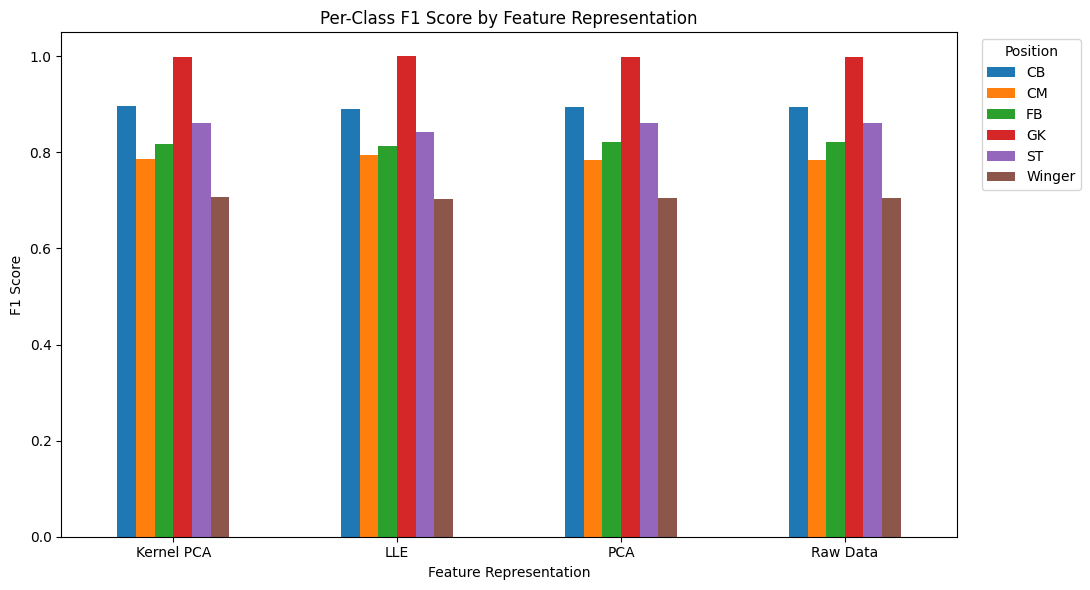

In [ ]:
per_class_rows = []

class_labels = sorted(y_test.unique())

for method_name, predictions in final_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_labels:
        per_class_rows.append({
            "Method": method_name,
            "Class": class_name,
            "F1 Score": report[class_name]["f1-score"]
        })


per_class_f1_df = pd.DataFrame(per_class_rows)

per_class_pivot = per_class_f1_df.pivot(
    index="Method",
    columns="Class",
    values="F1 Score"
)

ax = per_class_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Per-Class F1 Score by Feature Representation")
plt.ylabel("F1 Score")
plt.xlabel("Feature Representation")
plt.ylim(0, 1.05)

plt.legend(
    title="Position",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "../figures/per_class_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

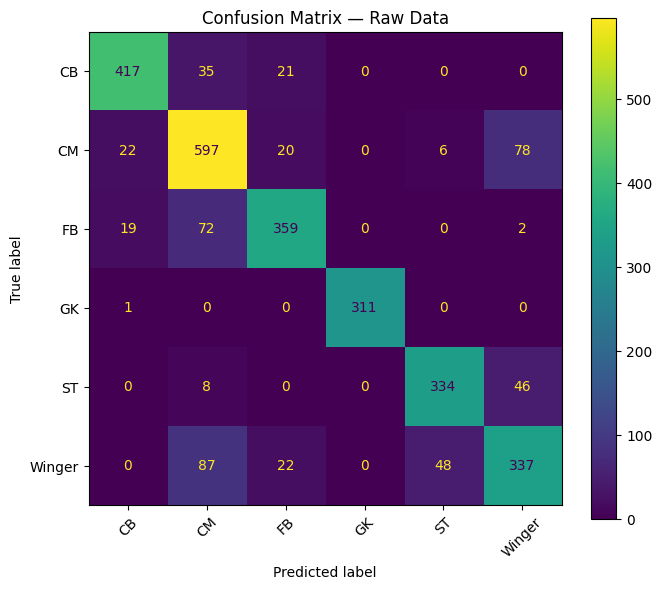

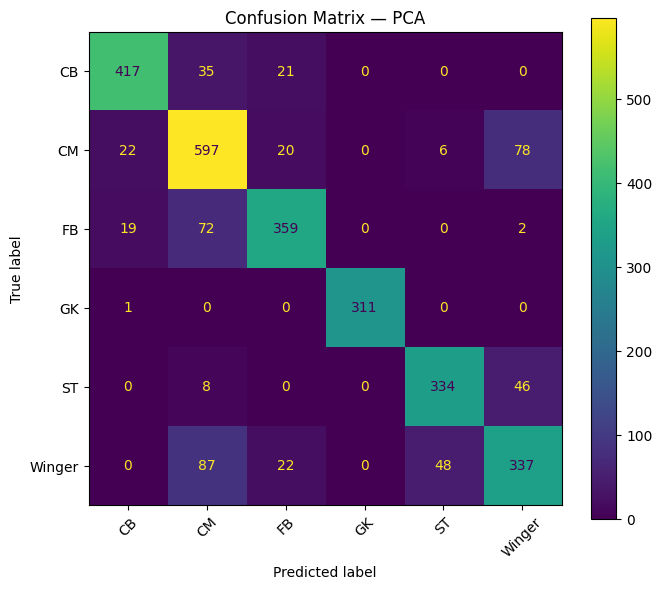

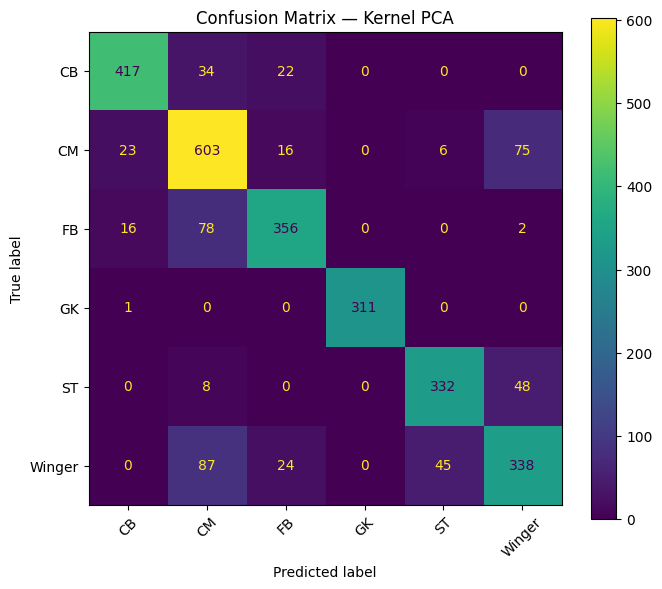

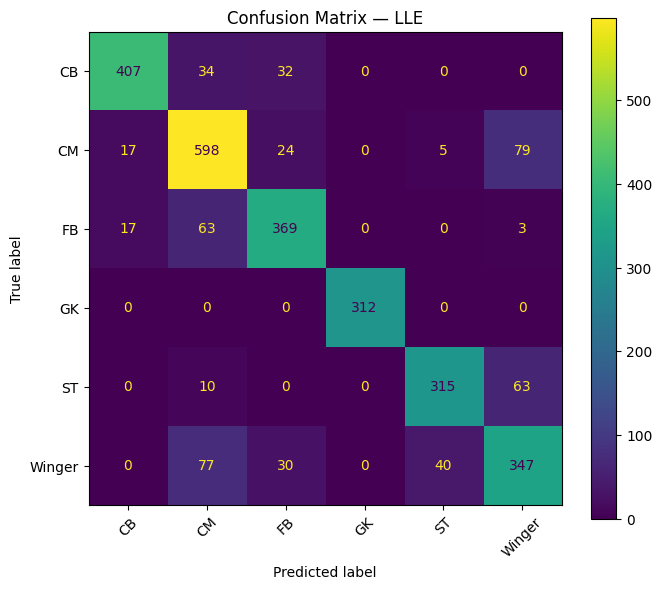

In [ ]:
class_labels = sorted(y_test.unique())

for method_name, predictions in final_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_labels
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(
        ax=ax,
        xticks_rotation=45,
        values_format="d"
    )

    ax.set_title(
        f"Confusion Matrix — {method_name}"
    )

    plt.tight_layout()

    filename = (
        method_name
        .lower()
        .replace(" ", "_")
    )

    plt.savefig(
        f"../figures/confusion_matrix_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

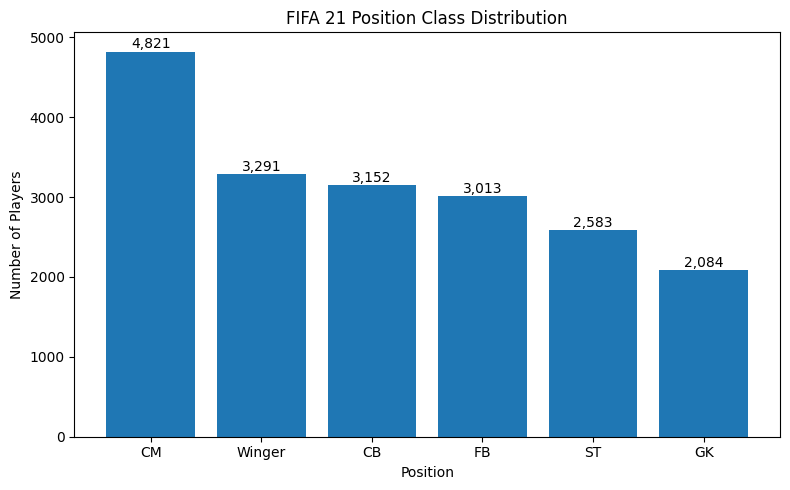

In [ ]:
class_counts = y.value_counts().sort_values(
    ascending=False
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("FIFA 21 Position Class Distribution")
plt.xlabel("Position")
plt.ylabel("Number of Players")

for bar, value in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 40,
        f"{value:,}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()